# 04 — Model training

This notebook fits the models that notebook 05 explains, on each branch: the original
series and its seasonal and trend components.

1. **SARIMAX first.** A seasonal ARIMA with the lagged climate predictors as regressors
   (Box et al., 2015). It is interpretable by construction: its coefficients state how much
   each term moves the forecast, with a standard error. Its specification is fixed by a rule
   and explained before any other model is fitted, so it is the reference against which the
   explanations of the other models are read.
2. **Five learned models**, each of which needs a post-hoc explanation: XGBoost (Chen and
   Guestrin, 2016) and Random Forest (Breiman, 2001), the tree ensembles of the wavelet
   framework; support vector regression (SVR; Drucker et al., 1997; Smola and Schölkopf, 2004),
   the regression form of the support vector machine (Cortes and Vapnik, 1995); a small
   feed-forward neural network (MLP; Rumelhart et al., 1986); and Ridge regression (Hoerl and
   Kennard, 1970), the linear contrast. Recurrent networks such as the LSTM are not used:
   twenty years of monthly values are too few for them (Hewamalage et al., 2021).

Accuracy is reported as context only: an explanation is worth comparing when the model
forecasts reasonably, and the question of this study is how the models explain the forecast,
not which one forecasts best. Scores: RMSE, R² and MAE (Hyndman and Koehler, 2006), on the
test period January 2022 to December 2024, evaluated once.

Input: `data/processed/features_*.csv` · Output: `results/04_*`

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
import warnings

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning as SMConvergenceWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from xgboost import XGBRegressor

# statsmodels warns when an optimiser stops early or start values are non-stationary;
# the fits are kept, and the residual checks below judge them
for w in (SMConvergenceWarning, UserWarning, FutureWarning):
    warnings.filterwarnings("ignore", category=w)

BRANCHES = ["original", "seasonal", "trend"]
SUFFIX = {"original": "", "seasonal": "_S", "trend": "_T"}
data = {b: pd.read_csv(f"../data/processed/features_{b}.csv",
                       index_col="date", parse_dates=True) for b in BRANCHES}


def split(df):
    X = df.drop(columns=["target", "split"])
    train = df["split"] == "train"
    return X[train], X[~train], df.loc[train, "target"], df.loc[~train, "target"]


for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    print(f"{b:9s} {Xtr.shape[1]:2d} features | "
          f"train {len(Xtr)} ({Xtr.index.min():%Y-%m}..{Xtr.index.max():%Y-%m}) | "
          f"test {len(Xte)} ({Xte.index.min():%Y-%m}..{Xte.index.max():%Y-%m})")

original  14 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
seasonal  17 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
trend      6 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)


## Reference: SARIMAX, specified before the other models

A seasonal ARIMA describes a series by its own past (Box et al., 2015): **autoregressive**
terms carry over part of the last months' departures, **moving-average** terms correct by the
last forecast errors, and the same two kinds of terms at a lag of twelve months describe how
this year's season repeats last year's. The series is first **differenced** (d ordinary,
D seasonal differences) until its level and seasonal pattern are stable. SARIMAX adds the
lagged climate predictors of the branch (notebook 03) as regressors: each coefficient is the
change in the forecast for one unit of that predictor, the rest of the model held fixed. This
is the model's explanation, stated by the model itself.

The orders are fixed by a rule, on the training months only, before any other model is
fitted:

1. **Seasonal differencing.** D = 1 when the seasonal strength of an STL decomposition
   (Cleveland et al., 1990), `1 − var(remainder) / var(seasonal + remainder)` (Wang et al.,
   2006), exceeds 0.64, the threshold of the `forecast` package's automatic ARIMA (Hyndman
   and Khandakar, 2008).
2. **Ordinary differencing.** d is the smallest number of differences after which the
   augmented Dickey–Fuller test rejects a unit root (Dickey and Fuller, 1979; Said and
   Dickey, 1984) and the KPSS test does not reject stationarity (Kwiatkowski et al., 1992),
   both at 5%. The two tests have opposite null hypotheses, so requiring both guards against
   the low power of each.
3. **Orders.** With d and D fixed, p and q from 0 to 2 and P and Q from 0 to 1 are chosen by
   AIC (Akaike, 1974), compared only between models with the same differencing. A constant is
   included only when nothing is differenced.
4. **Check.** The residuals are tested for remaining autocorrelation at 12 and 24 months
   (Ljung and Box, 1978); a small p-value means structure is left that the model has missed.

The orders are chosen on the series alone, then the climate regressors are added with the
same orders. Each coefficient is reported with its p-value, and with its effect for one
standard deviation of the predictor, so that terms in different units can be compared.

In [2]:
def climate(X):
    return [c for c in X.columns if c.startswith(("LST", "SPEI"))]


def seasonal_strength(y):
    fit = STL(y, period=12, robust=True).fit()
    return max(0.0, 1 - np.var(fit.resid) / np.var(fit.resid + fit.seasonal))


def choose_d(x):
    for d in range(3):
        z = np.diff(x, d) if d else x
        if adfuller(z, autolag="AIC")[1] < 0.05 and kpss(z, regression="c", nlags="auto")[1] > 0.05:
            return d
    return 2


def select_order(y):
    D = int(seasonal_strength(y) > 0.64)
    d = choose_d((y.diff(12).dropna() if D else y).to_numpy())
    trend = "c" if d + D == 0 else "n"
    fits = []
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    try:
                        r = SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, 12),
                                    trend=trend).fit(disp=False)
                        fits.append((r.aic, (p, d, q), (P, D, Q, 12)))
                    except Exception:
                        pass
    _, order, seasonal = min(fits)
    return dict(order=order, seasonal_order=seasonal, trend=trend)


sarimax_spec, sarimax_fit, coef_rows = {}, {}, []
for b, df in data.items():
    Xtr, _, ytr, _ = split(df)
    y, X = ytr.asfreq("MS"), Xtr[climate(Xtr)].asfreq("MS")
    spec = select_order(y)
    fit = SARIMAX(y, exog=X, **spec).fit(disp=False)
    d, D = spec["order"][1], spec["seasonal_order"][1]
    k = spec["order"][0] + spec["order"][2] + spec["seasonal_order"][0] + spec["seasonal_order"][2]
    lb = acorr_ljungbox(fit.resid[d + 12 * D:], lags=[12, 24], model_df=k)["lb_pvalue"]
    sarimax_spec[b], sarimax_fit[b] = {**spec, "lb12": lb.iloc[0], "lb24": lb.iloc[1]}, fit
    for term in fit.params.index:
        coef_rows.append(dict(branch=b, term=term, coef=fit.params[term], p=fit.pvalues[term],
                              effect_of_1sd=fit.params[term] * X[term].std() if term in X else np.nan))
    print(f"{b:9s} SARIMA{spec['order']}{spec['seasonal_order']}  climate {list(X.columns)}  "
          f"Ljung-Box p {lb.iloc[0]:.2f} (12), {lb.iloc[1]:.2f} (24)")

sarimax_coefs = pd.DataFrame(coef_rows)
print()
print(sarimax_coefs.round(4).to_string(index=False))


def sarimax_forecast(b, df):
    # parameters estimated on the training months, filter run through the test months
    y, X = df["target"].asfreq("MS"), df[climate(df)].asfreq("MS")
    run = sarimax_fit[b].apply(y, exog=X, refit=False)
    test_index = df.index[df["split"] == "test"]
    return run.predict(start=test_index[0], end=test_index[-1])

original  SARIMA(2, 0, 0)(1, 1, 1, 12)  climate ['SPEI_6_lag2', 'LST_lag1']  Ljung-Box p 0.83 (12), 0.41 (24)


seasonal  SARIMA(2, 0, 1)(0, 1, 1, 12)  climate ['SPEI_6_S_lag3', 'LST_S_lag1']  Ljung-Box p 0.00 (12), 0.00 (24)


trend     SARIMA(2, 1, 1)(1, 0, 1, 12)  climate ['SPEI_48_T_lag11', 'LST_T_lag1']  Ljung-Box p 0.00 (12), 0.00 (24)

  branch            term    coef      p  effect_of_1sd
original     SPEI_6_lag2  0.0131 0.0004         0.0131
original        LST_lag1 -0.0044 0.0020        -0.0492
original           ar.L1  0.7374 0.0000            NaN
original           ar.L2 -0.1752 0.0093            NaN
original        ar.S.L12 -0.2533 0.0002            NaN
original        ma.S.L12 -0.7531 0.0000            NaN
original          sigma2  0.0015 0.0000            NaN
seasonal   SPEI_6_S_lag3  0.0130 0.0018         0.0102
seasonal      LST_S_lag1 -0.0041 0.0039        -0.0456
seasonal           ar.L1  1.4958 0.0000            NaN
seasonal           ar.L2 -0.6396 0.0000            NaN
seasonal           ma.L1 -0.9994 0.6104            NaN
seasonal        ma.S.L12 -0.9997 0.9456            NaN
seasonal          sigma2  0.0011 0.9451            NaN
   trend SPEI_48_T_lag11 -0.0075 0.4015        -0.0068
   

**What SARIMAX says.** On the original series the rule chose SARIMA(2,0,0)(1,1,1)₁₂, and its
residuals show no structure left (Ljung–Box p = 0.83 and 0.41). Read term by term:

- **Own past.** About 74% of last month's departure from the seasonal pattern carries into
  this month (ar.L1 = 0.74), partly undone the month after (ar.L2 = −0.18); the seasonal terms
  at twelve months adjust this year's season by last year's.
- **LST.** One degree warmer in the previous month lowers this month's NDVI by 0.0044
  (p = 0.002), or 0.049 for one standard deviation of LST.
- **SPEI-6.** One unit wetter two months earlier raises NDVI by 0.013 (p < 0.001), the same
  for one standard deviation.

LST therefore moves the forecast about four times as much as SPEI per standard deviation.
On the seasonal component the two climate coefficients are nearly the same (−0.0041 and
+0.013), but the model itself is poorly behaved: its moving-average terms are at −1, the sign
that seasonal differencing removed a season that was already regular, and its residuals keep
structure (Ljung–Box p < 0.01). On the trend component, LST is significant and negative,
SPEI-48 is not, and the residuals keep structure too. The SARIMAX reference is therefore
sound on the original series and only indicative on the components.

## Hyperparameter tuning

Randomised search (100 draws) for the tree models, SVR and the MLP, which samples a wide
space more efficiently than a grid (Bergstra and Bengio, 2012), and grid search over 101
penalties for Ridge, all scored by mean squared error on a five-fold `TimeSeriesSplit` of the
training period, in which every validation fold follows its training data (Bergmeir and
Benítez, 2012). Ridge, SVR and the MLP are standardised inside their pipelines, so scaling
uses training statistics only; SVR and the MLP also standardise the target, so ε and the
penalties mean the same on every branch. The MLP is trained by L-BFGS (Liu and Nocedal,
1989), which converges reliably on a few hundred samples. Any tuned value within 5% of the
edge of its range is reported, since a value on the edge means the search wanted to go
further.

In [3]:
SEED = 0
CV = TimeSeriesSplit(n_splits=5)
N_ITER = 100

# Ranges wide enough that no tuned value should sit on an edge; at_edge() below
# reports any that does.
def scaled(est):
    return TransformedTargetRegressor(make_pipeline(StandardScaler(), est),
                                      transformer=StandardScaler())


MODELS = {
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(100, 3001), "max_depth": randint(1, 9),
        "learning_rate": loguniform(0.0005, 0.3), "subsample": uniform(0.3, 0.7),
        "colsample_bytree": uniform(0.3, 0.7), "min_child_weight": randint(1, 21),
        "reg_lambda": loguniform(0.01, 100)}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(200, 1000), "max_depth": [None, 2, 3, 4, 6, 8, 12, 16],
        "min_samples_leaf": randint(1, 21), "max_features": ["sqrt", 0.33, 0.5, 0.75, 1.0]}),
    "MLP": (scaled(MLPRegressor(solver="lbfgs", max_iter=5000, random_state=SEED)), {
        "regressor__mlpregressor__hidden_layer_sizes": [(4,), (8,), (16,), (32,), (8, 4), (16, 8)],
        "regressor__mlpregressor__alpha": loguniform(1e-4, 1e2),
        "regressor__mlpregressor__activation": ["relu", "tanh"]}),
    "SVR": (scaled(SVR()), {
        "regressor__svr__C": loguniform(1e-2, 1e3),
        "regressor__svr__gamma": loguniform(1e-4, 1),
        "regressor__svr__epsilon": loguniform(1e-3, 1)}),
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {
        "ridge__alpha": np.logspace(-6, 4, 101)}),
}


def tune(name, X, y):
    est, space = MODELS[name]
    if name == "Ridge":
        search = GridSearchCV(est, space, cv=CV,
                              scoring="neg_mean_squared_error", n_jobs=-1)
    else:
        search = RandomizedSearchCV(est, space, n_iter=N_ITER, cv=CV,
                                    scoring="neg_mean_squared_error",
                                    random_state=SEED, n_jobs=-1)
    return search.fit(X, y)


def at_edge(name, params):
    """Tuned values within 5% (log scale for rates) of the edge of their range."""
    hits = []
    for k, v in params.items():
        dist = MODELS[name][1][k]
        if isinstance(dist, list) or not isinstance(v, (int, float)):
            vals = list(dist)
            if v in (vals[0], vals[-1]) and len(vals) > 2:
                hits.append(f"{k}={v}")
            continue
        if hasattr(dist, "support"):
            lo, hi = dist.support()
        else:
            lo, hi = min(dist), max(dist)
        log = k in ("learning_rate", "reg_lambda", "ridge__alpha", "regressor__svr__C",
                    "regressor__svr__gamma", "regressor__svr__epsilon",
                    "regressor__mlpregressor__alpha")
        f = (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo)) if log else (v - lo) / (hi - lo)
        if f < 0.05 or f > 0.95:
            hits.append(f"{k}={v:.4g}")
    return hits


# the models with a random component, and the parameter that seeds it
SEEDED = {"XGBoost": "random_state", "RandomForest": "random_state",
          "MLP": "regressor__mlpregressor__random_state"}

best_params, cv_rmse = {}, {}
for b, df in data.items():
    Xtr, _, ytr, _ = split(df)
    for name in MODELS:
        search = tune(name, Xtr, ytr)
        best_params[(b, name)] = search.best_params_
        cv_rmse[(b, name)] = np.sqrt(-search.best_score_)
        edge = at_edge(name, search.best_params_)
        print(f"{b:9s} {name:12s} CV RMSE {cv_rmse[(b, name)]:.4f}   "
              f"at an edge: {', '.join(edge) if edge else 'none'}")

original  XGBoost      CV RMSE 0.0480   at an edge: max_depth=8


original  RandomForest CV RMSE 0.0495   at an edge: none


original  MLP          CV RMSE 0.0450   at an edge: none


original  SVR          CV RMSE 0.0449   at an edge: none


original  Ridge        CV RMSE 0.0523   at an edge: none


seasonal  XGBoost      CV RMSE 0.0437   at an edge: colsample_bytree=0.3082, n_estimators=2950


... (5 outputs left out)

trend     RandomForest CV RMSE 0.0059   at an edge: max_depth=None, max_features=1.0


trend     MLP          CV RMSE 0.0046   at an edge: regressor__mlpregressor__alpha=0.0001553, regressor__mlpregressor__hidden_layer_sizes=(4,)


trend     SVR          CV RMSE 0.0026   at an edge: regressor__svr__C=645.2


trend     Ridge        CV RMSE 0.0020   at an edge: ridge__alpha=1e-06


## Test period

Accuracy as context for the explanations: SARIMAX and the five learned models beside two
baselines (Hyndman and Athanasopoulos, 2021, sec. 5.2). **Persistence** predicts last month's
value. **Climatology** predicts the training-period mean for the calendar month. A model that
cannot beat climatology has learned nothing beyond the average season, and its explanation
would describe little.

In [4]:
def make_model(b, name, seed=SEED):
    est = clone(MODELS[name][0]).set_params(**best_params[(b, name)])
    if name in SEEDED:
        est.set_params(**{SEEDED[name]: seed})
    return est


def scores(y, p):
    return dict(RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p),
                MAE=mean_absolute_error(y, p))


def baselines(b, df, test_mask):
    y = df["target"]
    persistence = df[f"NDVI{SUFFIX[b]}_lag1"]
    clim = y[~test_mask].groupby(y[~test_mask].index.month).mean()
    climatology = pd.Series(y.index.month.map(clim), index=y.index)
    return {"persistence": persistence, "climatology": climatology}


rows, predictions = [], {}
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    test = df["split"] == "test"
    for name in MODELS:
        p = make_model(b, name).fit(Xtr, ytr).predict(Xte)
        predictions[(b, name)] = pd.Series(p, index=Xte.index)
        rows.append(dict(branch=b, model=name, **scores(yte, p)))
    p = sarimax_forecast(b, df)
    predictions[(b, "SARIMAX")] = p
    rows.append(dict(branch=b, model="SARIMAX", **scores(yte, p)))
    for name, s in baselines(b, df, test).items():
        predictions[(b, name)] = s[test]
        rows.append(dict(branch=b, model=name, **scores(yte, s[test])))

test_scores = pd.DataFrame(rows)
ORDER = ["SARIMAX", "XGBoost", "RandomForest", "MLP", "SVR", "Ridge", "persistence", "climatology"]
for metric in ["RMSE", "R2", "MAE"]:
    print(f"\n{metric}")
    print(test_scores.pivot(index="model", columns="branch", values=metric)
                     .loc[ORDER, BRANCHES].round(4).to_string())


RMSE
branch        original  seasonal   trend
model                                   
SARIMAX         0.0541    0.0536  0.0009
XGBoost         0.0536    0.0553  0.0091
RandomForest    0.0583    0.0571  0.0062
MLP             0.0513    0.0514  0.0027
SVR             0.0534    0.0579  0.0032
Ridge           0.0597    0.0587  0.0021
persistence     0.0972    0.0971  0.0021
climatology     0.0751    0.0733  0.0404

R2
branch        original  seasonal   trend
model                                   
SARIMAX         0.8816    0.8808  0.9980
XGBoost         0.8839    0.8732  0.7998
RandomForest    0.8623    0.8647  0.9077
MLP             0.8934    0.8903  0.9826
SVR             0.8845    0.8610  0.9752
Ridge           0.8560    0.8574  0.9896
persistence     0.6179    0.6092  0.9893
climatology     0.7719    0.7774 -2.9469

MAE
branch        original  seasonal   trend
model                                   
SARIMAX         0.0357    0.0379  0.0007
XGBoost         0.0368    0.0401  0.0080
R

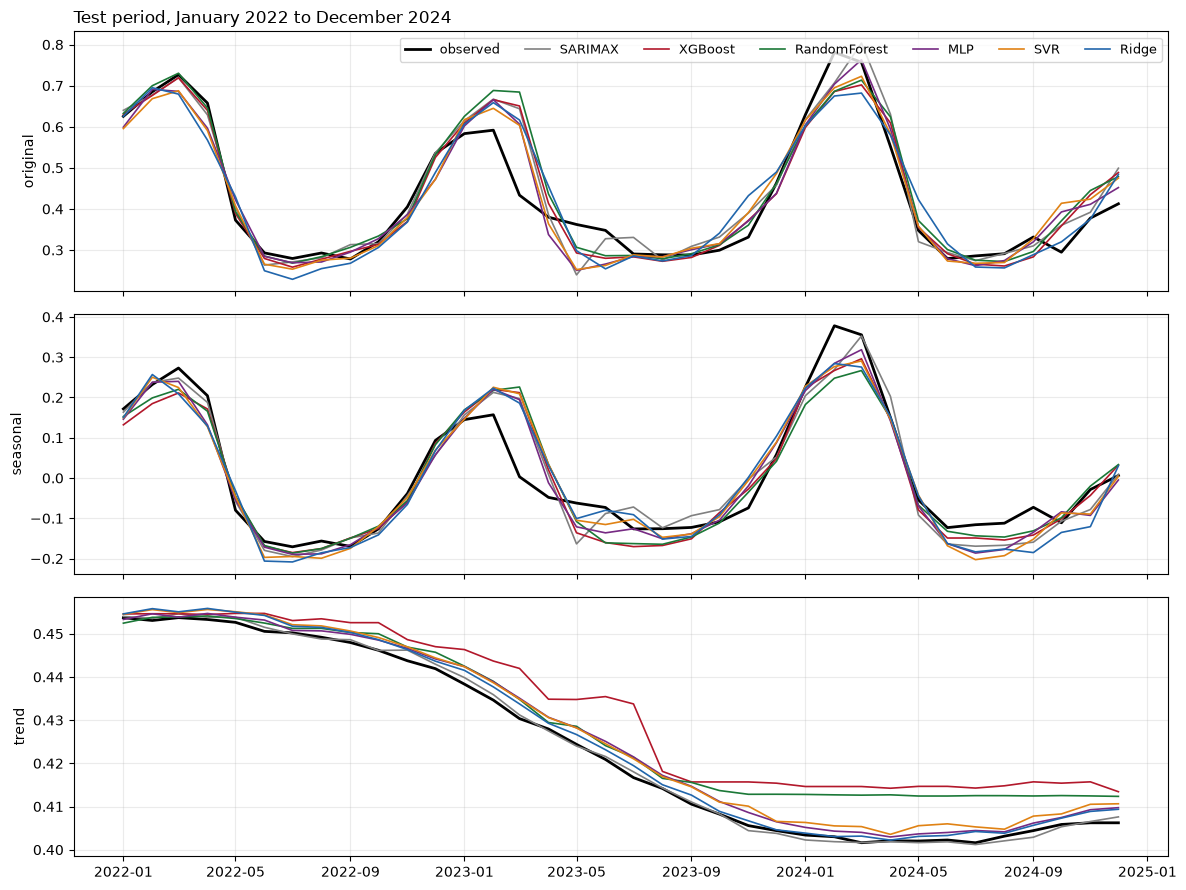

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
colors = {"SARIMAX": "grey", "XGBoost": "#b2182b", "RandomForest": "#1b7837",
          "MLP": "#762a83", "SVR": "#e08214", "Ridge": "#2166ac"}
for ax, b in zip(axes, BRANCHES):
    _, Xte, _, yte = split(data[b])
    ax.plot(yte.index, yte, color="black", lw=2, label="observed")
    for name, c in colors.items():
        ax.plot(yte.index, predictions[(b, name)], color=c, lw=1.2, label=name)
    ax.set_ylabel(b)
    ax.grid(alpha=0.25)
axes[0].legend(ncol=7, loc="upper right", fontsize=9)
axes[0].set_title("Test period, January 2022 to December 2024", loc="left")
fig.tight_layout()
fig.savefig("../figures/04_test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

## Noise floor

XGBoost, Random Forest and the MLP refitted with 20 seeds at their tuned parameters. A
difference smaller than the seed-to-seed standard deviation is indistinguishable from
refitting. Ridge and SVR are deterministic.

In [6]:
floor = []
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    for name in MODELS:
        seeds = range(20) if name in SEEDED else [SEED]
        runs = [scores(yte, make_model(b, name, s).fit(Xtr, ytr).predict(Xte)) for s in seeds]
        floor.append(dict(branch=b, model=name,
                          RMSE_mean=np.mean([r["RMSE"] for r in runs]),
                          RMSE_sd=np.std([r["RMSE"] for r in runs]),
                          R2_mean=np.mean([r["R2"] for r in runs]),
                          R2_sd=np.std([r["R2"] for r in runs])))

noise_floor = pd.DataFrame(floor)
print(noise_floor.round(4).to_string(index=False))

  branch        model  RMSE_mean  RMSE_sd  R2_mean  R2_sd
original      XGBoost     0.0539   0.0004   0.8824 0.0019
original RandomForest     0.0584   0.0005   0.8619 0.0022
original          MLP     0.0505   0.0017   0.8968 0.0069
original          SVR     0.0534   0.0000   0.8845 0.0000
original        Ridge     0.0597   0.0000   0.8560 0.0000
seasonal      XGBoost     0.0548   0.0004   0.8757 0.0019
seasonal RandomForest     0.0572   0.0003   0.8641 0.0014
seasonal          MLP     0.0527   0.0015   0.8847 0.0067
seasonal          SVR     0.0579   0.0000   0.8610 0.0000
seasonal        Ridge     0.0587   0.0000   0.8574 0.0000
   trend      XGBoost     0.0089   0.0011   0.8065 0.0461
   trend RandomForest     0.0061   0.0000   0.9093 0.0011
   trend          MLP     0.0031   0.0009   0.9746 0.0145
   trend          SVR     0.0032   0.0000   0.9752 0.0000
   trend        Ridge     0.0021   0.0000   0.9896 0.0000


## Rolling-origin evaluation

One test period can be unusually easy or hard, so five consecutive three-year windows are
forecast, each by models trained on everything before it (rolling origin; Tashman, 2000).
Each of the four earlier windows is tuned again, by the same search, on its own training
years only, so no window is scored with settings chosen on data that includes it. The last
window is the test period and keeps the tuning above.

In [7]:
WINDOWS = [("2010-01-01", "2012-12-01"), ("2013-01-01", "2015-12-01"),
           ("2016-01-01", "2018-12-01"), ("2019-01-01", "2021-12-01"),
           ("2022-01-01", "2024-12-01")]

# Each window is tuned again on its own training years, so no window is scored with
# settings chosen on data that includes it. The last window is the test period and
# keeps the tuning above, which used the same training years.
window_params, folds = {}, []
for b, df in data.items():
    X, y = df.drop(columns=["target", "split"]), df["target"]
    for start, end in WINDOWS:
        tr, te = df.index < start, (df.index >= start) & (df.index <= end)
        label = start[:4] + "-" + end[2:4]
        for name in MODELS:
            if start == WINDOWS[-1][0]:
                params = best_params[(b, name)]
            else:
                params = tune(name, X[tr], y[tr]).best_params_
            window_params[(b, label, name)] = params
            est = clone(MODELS[name][0]).set_params(**params)
            p = est.fit(X[tr], y[tr]).predict(X[te])
            folds.append(dict(branch=b, window=label, model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], p)),
                              R2=r2_score(y[te], p)))
        for name, s in baselines(b, df, ~tr).items():
            folds.append(dict(branch=b, window=start[:4] + "-" + end[2:4], model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], s[te])),
                              R2=r2_score(y[te], s[te])))

rolling = pd.DataFrame(folds)
order = ["XGBoost", "RandomForest", "MLP", "SVR", "Ridge", "persistence", "climatology"]
for b in BRANCHES:
    for metric, digits in [("RMSE", 4), ("R2", 3)]:
        t = rolling[rolling.branch == b].pivot(index="model", columns="window",
                                               values=metric).loc[order]
        t["mean"], t["sd"] = t.mean(axis=1), t.std(axis=1)
        print(f"\n{b} — {metric}"); print(t.round(digits).to_string())


original — RMSE
window        2010-12  2013-15  2016-18  2019-21  2022-24    mean      sd
model                                                                    
XGBoost        0.0601   0.0373   0.0453   0.0377   0.0536  0.0468  0.0100
RandomForest   0.0613   0.0328   0.0455   0.0411   0.0583  0.0478  0.0120
MLP            0.0608   0.0388   0.0371   0.0382   0.0513  0.0452  0.0104
SVR            0.0551   0.0448   0.0432   0.0330   0.0534  0.0459  0.0089
Ridge          0.0608   0.0436   0.0491   0.0422   0.0597  0.0511  0.0088
persistence    0.0999   0.1034   0.1098   0.1012   0.0972  0.1023  0.0048
climatology    0.0758   0.0357   0.0581   0.0522   0.0751  0.0594  0.0168

original — R2
window        2010-12  2013-15  2016-18  2019-21  2022-24   mean     sd
model                                                                  
XGBoost         0.872    0.948    0.938    0.954    0.884  0.919  0.038
RandomForest    0.867    0.960    0.937    0.945    0.862  0.914  0.046
MLP           

## Reconstruction

Seasonal plus trend predictions, compared with the model fitted to the original
series directly.

In [8]:
y_orig = split(data["original"])[3]
recon = []
for name in MODELS:
    p = (predictions[("seasonal", name)] + predictions[("trend", name)]).reindex(y_orig.index)
    direct = test_scores.query("branch == 'original' and model == @name").iloc[0]
    recon.append(dict(model=name,
                      RMSE_direct=direct.RMSE, RMSE_reconstructed=np.sqrt(mean_squared_error(y_orig, p)),
                      R2_direct=direct.R2, R2_reconstructed=r2_score(y_orig, p)))
print(pd.DataFrame(recon).round(4).to_string(index=False))

       model  RMSE_direct  RMSE_reconstructed  R2_direct  R2_reconstructed
     XGBoost       0.0536              0.0542     0.8839            0.8810
RandomForest       0.0583              0.0560     0.8623            0.8733
         MLP       0.0513              0.0514     0.8934            0.8933
         SVR       0.0534              0.0577     0.8845            0.8652
       Ridge       0.0597              0.0586     0.8560            0.8613


## Limitations

1. **Two-sided components.** The seasonal and trend branches, and the reconstruction, use
   wavelet components that see later months (notebook 02), so their scores overstate what a
   real forecast could reach (Du et al., 2017). The original branch is free of this.
2. **SARIMAX orders are chosen on the series alone**, then the climate regressors are
   added; choosing them with the regressors could give other orders. SARIMAX is evaluated on
   the test period but not over the rolling windows.
3. **Composite timing.** Part of the most recent monthly NDVI comes from the first days of
   the month being forecast (notebook 02). The effect is the same for every model.
4. **Trees cannot extrapolate.** On the trend branch, values outside the training range
   cannot be produced by the tree models, which is why they fail there.
5. **Uncertainty.** The noise floor covers refitting with other seeds, not other training
   periods or sites.

## Saving

In [9]:
json.dump({f"{b}|{m}": {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
           for (b, m), p in best_params.items()},
          open("../results/04_best_params.json", "w"), indent=2)
test_scores.to_csv("../results/04_test_scores.csv", index=False)
noise_floor.to_csv("../results/04_noise_floor.csv", index=False)
rolling.to_csv("../results/04_rolling_origin.csv", index=False)
json.dump({f"{b}|{w}|{m}": {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
           for (b, w, m), p in window_params.items()},
          open("../results/04_window_params.json", "w"), indent=2)
pd.DataFrame({f"{b}|{m}": s for (b, m), s in predictions.items()}) \
  .to_csv("../results/04_test_predictions.csv")
json.dump({b: {k: (list(v) if isinstance(v, tuple) else v) for k, v in s.items()}
           for b, s in sarimax_spec.items()}, open("../results/04_sarimax_spec.json", "w"), indent=2)
sarimax_coefs.to_csv("../results/04_sarimax_coefficients.csv", index=False)
print("saved")

saved


## References

- Akaike, H. (1974). A new look at the statistical model identification. IEEE Transactions on Automatic Control, 19(6), 716–723.
- Bergmeir, C. & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. Information Sciences, 191, 192–213.
- Bergstra, J. & Bengio, Y. (2012). Random search for hyper-parameter optimization. Journal of Machine Learning Research, 13, 281–305.
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. & Ljung, G. M. (2015). Time Series Analysis: Forecasting and Control (5th ed.). Wiley.
- Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5–32.
- Chen, T. & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785–794.
- Cleveland, R. B., Cleveland, W. S., McRae, J. E. & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on loess. Journal of Official Statistics, 6(1), 3–73.
- Cortes, C. & Vapnik, V. (1995). Support-vector networks. Machine Learning, 20(3), 273–297.
- Dickey, D. A. & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. Journal of the American Statistical Association, 74(366), 427–431.
- Drucker, H., Burges, C. J. C., Kaufman, L., Smola, A. & Vapnik, V. (1997). Support vector regression machines. Advances in Neural Information Processing Systems, 9, 155–161.
- Du, K., Zhao, Y. & Lei, J. (2017). The incorrect usage of singular spectral analysis and discrete wavelet transform in hybrid models to predict hydrological time series. Journal of Hydrology, 552, 44–51. https://doi.org/10.1016/j.jhydrol.2017.06.019
- Hewamalage, H., Bergmeir, C. & Bandara, K. (2021). Recurrent neural networks for time series forecasting: current status and future directions. International Journal of Forecasting, 37(1), 388–427.
- Hoerl, A. E. & Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. Technometrics, 12(1), 55–67.
- Hyndman, R. J. & Athanasopoulos, G. (2021). Forecasting: Principles and Practice (3rd ed.). OTexts, Melbourne. https://otexts.com/fpp3/
- Hyndman, R. J. & Khandakar, Y. (2008). Automatic time series forecasting: the forecast package for R. Journal of Statistical Software, 27(3), 1–22.
- Hyndman, R. J. & Koehler, A. B. (2006). Another look at measures of forecast accuracy. International Journal of Forecasting, 22(4), 679–688.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P. & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. Journal of Econometrics, 54(1–3), 159–178.
- Liu, D. C. & Nocedal, J. (1989). On the limited memory BFGS method for large scale optimization. Mathematical Programming, 45, 503–528.
- Ljung, G. M. & Box, G. E. P. (1978). On a measure of lack of fit in time series models. Biometrika, 65(2), 297–303.
- Rumelhart, D. E., Hinton, G. E. & Williams, R. J. (1986). Learning representations by back-propagating errors. Nature, 323, 533–536.
- Said, S. E. & Dickey, D. A. (1984). Testing for unit roots in autoregressive-moving average models of unknown order. Biometrika, 71(3), 599–607.
- Smola, A. J. & Schölkopf, B. (2004). A tutorial on support vector regression. Statistics and Computing, 14(3), 199–222.
- Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. International Journal of Forecasting, 16(4), 437–450.
- Wang, X., Smith, K. & Hyndman, R. (2006). Characteristic-based clustering for time series data. Data Mining and Knowledge Discovery, 13(3), 335–364.